② 학습 데이터 로드

In [1]:

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold
)

# 데이터 경로
DATA_DIR = Path("../data")

train = pd.read_csv(DATA_DIR / "train.csv")

# 입력 변수와 정답 분리
gene_cols = train.columns.drop(
    ["ID", "SUBCLASS"]
).tolist()

X = train[gene_cols].copy()
y = train["SUBCLASS"].copy()

print("[데이터 준비 완료]")
print("X:", X.shape)
print("y:", y.shape)
print("Classes:", y.nunique())


[데이터 준비 완료]
X: (6201, 4384)
y: (6201,)
Classes: 26


③ 동일 유전자 프로파일 그룹 생성

In [2]:

# 유전자 프로파일을 기준으로 그룹 ID 생성
profile_hash = pd.util.hash_pandas_object(
    X,
    index=False
)

groups = pd.factorize(profile_hash)[0]

print("[프로파일 그룹 분석]")
print("전체 샘플:", len(X))
print("고유 프로파일:", len(np.unique(groups)))
print("중복 프로파일:", len(X) - len(np.unique(groups)))

# 동일 프로파일에서 암종이 서로 다른 경우 확인
profile_label_df = pd.DataFrame({
    "Group": groups,
    "SUBCLASS": y.values
})

label_counts = (
    profile_label_df
    .groupby("Group")["SUBCLASS"]
    .nunique()
)

conflicting_groups = (label_counts > 1).sum()

print("서로 다른 암종을 가진 프로파일 그룹:",
      conflicting_groups)


[프로파일 그룹 분석]
전체 샘플: 6201
고유 프로파일: 5636
중복 프로파일: 565
서로 다른 암종을 가진 프로파일 그룹: 447


④ 두 가지 교차검증 방식 비교

In [3]:

# 교차검증 설정
cv_methods = {
    "StratifiedKFold": StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    "StratifiedGroupKFold": StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )
}

results = []

for method_name, cv in cv_methods.items():

    if method_name == "StratifiedGroupKFold":
        splits = cv.split(X, y, groups)
    else:
        splits = cv.split(X, y)

    for fold, (train_idx, valid_idx) in enumerate(
        splits, start=1
    ):

        train_groups = set(groups[train_idx])
        valid_groups = set(groups[valid_idx])

        overlap = len(train_groups & valid_groups)

        train_classes = y.iloc[train_idx].nunique()
        valid_classes = y.iloc[valid_idx].nunique()

        results.append({
            "Method": method_name,
            "Fold": fold,
            "Train_Size": len(train_idx),
            "Valid_Size": len(valid_idx),
            "Train_Classes": train_classes,
            "Valid_Classes": valid_classes,
            "Group_Overlap": overlap
        })

cv_results = pd.DataFrame(results)

display(cv_results)


,Method,Fold,Train_Size,Valid_Size,Train_Classes,Valid_Classes,Group_Overlap
0,StratifiedKFold,1,4960,1241,26,26,151
1,StratifiedKFold,2,4961,1240,26,26,151
2,StratifiedKFold,3,4961,1240,26,26,146
3,StratifiedKFold,4,4961,1240,26,26,153
4,StratifiedKFold,5,4961,1240,26,26,137
5,StratifiedGroupKFold,1,4960,1241,26,26,0
6,StratifiedGroupKFold,2,4961,1240,26,26,0
7,StratifiedGroupKFold,3,4960,1241,26,26,0
8,StratifiedGroupKFold,4,4962,1239,26,26,0
9,StratifiedGroupKFold,5,4961,1240,26,26,0


⑤ Fold별 클래스 분포 비교

In [4]:

for method_name, cv in cv_methods.items():

    print(f"\n[{method_name}]")

    if method_name == "StratifiedGroupKFold":
        splits = cv.split(X, y, groups)
    else:
        splits = cv.split(X, y)

    fold_distributions = {}

    for fold, (_, valid_idx) in enumerate(
        splits, start=1
    ):
        counts = (
            y.iloc[valid_idx]
            .value_counts()
            .reindex(sorted(y.unique()), fill_value=0)
        )

        fold_distributions[f"Fold_{fold}"] = counts

    distribution_df = pd.DataFrame(
        fold_distributions
    )

    display(distribution_df)



[StratifiedKFold]


,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
SUBCLASS,,,,,
ACC,14,14,15,15,14
BLCA,21,21,21,21,20
BRCA,157,157,157,158,157
CESC,31,31,31,31,31
COAD,45,45,44,44,45
DLBC,8,7,7,8,8
GBMLGG,92,92,92,93,92
HNSC,44,45,45,45,44
KIPAN,103,103,103,103,103



[StratifiedGroupKFold]


,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
SUBCLASS,,,,,
ACC,14,15,15,14,14
BLCA,20,21,21,21,21
BRCA,157,157,157,157,158
CESC,31,31,31,31,31
COAD,44,44,45,45,45
DLBC,7,7,8,8,8
GBMLGG,92,93,92,92,92
HNSC,44,45,45,45,44
KIPAN,103,103,103,103,103


In [5]:
from scipy.sparse import csr_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)
from sklearn.model_selection import StratifiedGroupKFold
import time

② Binary Mutation 인코딩

In [6]:
# Train 데이터만 사용
X_binary = csr_matrix(
    X.ne("WT").to_numpy(dtype=np.uint8)
)

print("[Binary Mutation 인코딩]")
print("Shape:", X_binary.shape)
print("Non-zero:", X_binary.nnz)
print("Sparsity:",
      round(1 - X_binary.nnz / np.prod(X_binary.shape), 6))

[Binary Mutation 인코딩]
Shape: (6201, 4384)
Non-zero: 218893
Sparsity: 0.991948


③ StratifiedGroupKFold 모델 학습

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:

# 교차검증
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_scores = []

# OOF 예측 저장
oof_pred = np.empty(len(y), dtype=object)

start_time = time.time()

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_binary, y, groups),
    start=1
):
    print(f"\n===== Fold {fold} =====")

    X_tr = X_binary[train_idx]
    X_val = X_binary[valid_idx]

    y_tr = y.iloc[train_idx]
    y_val = y.iloc[valid_idx]

    # 기본 모델
    model = LogisticRegression(
        C=1.0,
        max_iter=2000,
        solver="lbfgs",
        class_weight=None
    )

    # 학습
    model.fit(X_tr, y_tr)

    # 검증 예측
    pred = model.predict(X_val)

    # OOF 저장
    oof_pred[valid_idx] = pred

    # 평가
    macro_f1 = f1_score(
        y_val, pred, average="macro"
    )

    accuracy = accuracy_score(y_val, pred)

    fold_scores.append({
        "Fold": fold,
        "Macro_F1": macro_f1,
        "Accuracy": accuracy
    })

    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Accuracy: {accuracy:.4f}")

# 결과 정리
baseline_results = pd.DataFrame(fold_scores)

print("\n===== 5-Fold 결과 =====")
display(baseline_results)

print(
    "Mean Macro F1:",
    round(baseline_results["Macro_F1"].mean(), 4)
)

print(
    "Std Macro F1:",
    round(baseline_results["Macro_F1"].std(), 4)
)

print(
    "Overall OOF Macro F1:",
    round(f1_score(y, oof_pred, average="macro"), 4)
)

print(
    "Total Time (sec):",
    round(time.time() - start_time, 2)
)



===== Fold 1 =====
Macro F1: 0.3250
Accuracy: 0.3650

===== Fold 2 =====
Macro F1: 0.3232
Accuracy: 0.3750

===== Fold 3 =====
Macro F1: 0.3076
Accuracy: 0.3642

===== Fold 4 =====
Macro F1: 0.3516
Accuracy: 0.3906

===== Fold 5 =====
Macro F1: 0.3311
Accuracy: 0.3774

===== 5-Fold 결과 =====


,Fold,Macro_F1,Accuracy
0,1,0.325037,0.365028
1,2,0.323213,0.375000
2,3,0.307640,0.364222
3,4,0.351622,0.390638
4,5,0.331145,0.377419


Mean Macro F1: 0.3277
Std Macro F1: 0.0159
Overall OOF Macro F1: 0.3298
Total Time (sec): 7.28


④ 암종별 F1 Score 확인

[암종별 OOF 성능]


,precision,recall,f1-score,support
THYM,0.071429,0.020408,0.031746,98.0
CESC,0.086957,0.038710,0.053571,155.0
SARC,0.171429,0.151515,0.160858,198.0
PAAD,0.262295,0.133333,0.176796,120.0
LIHC,0.351852,0.120253,0.179245,158.0
BLCA,0.444444,0.115385,0.183206,104.0
DLBC,1.000000,0.105263,0.190476,38.0
LUAD,0.287129,0.157609,0.203509,184.0
PCPG,0.214286,0.204082,0.209059,147.0
LUSC,0.298969,0.162921,0.210909,178.0


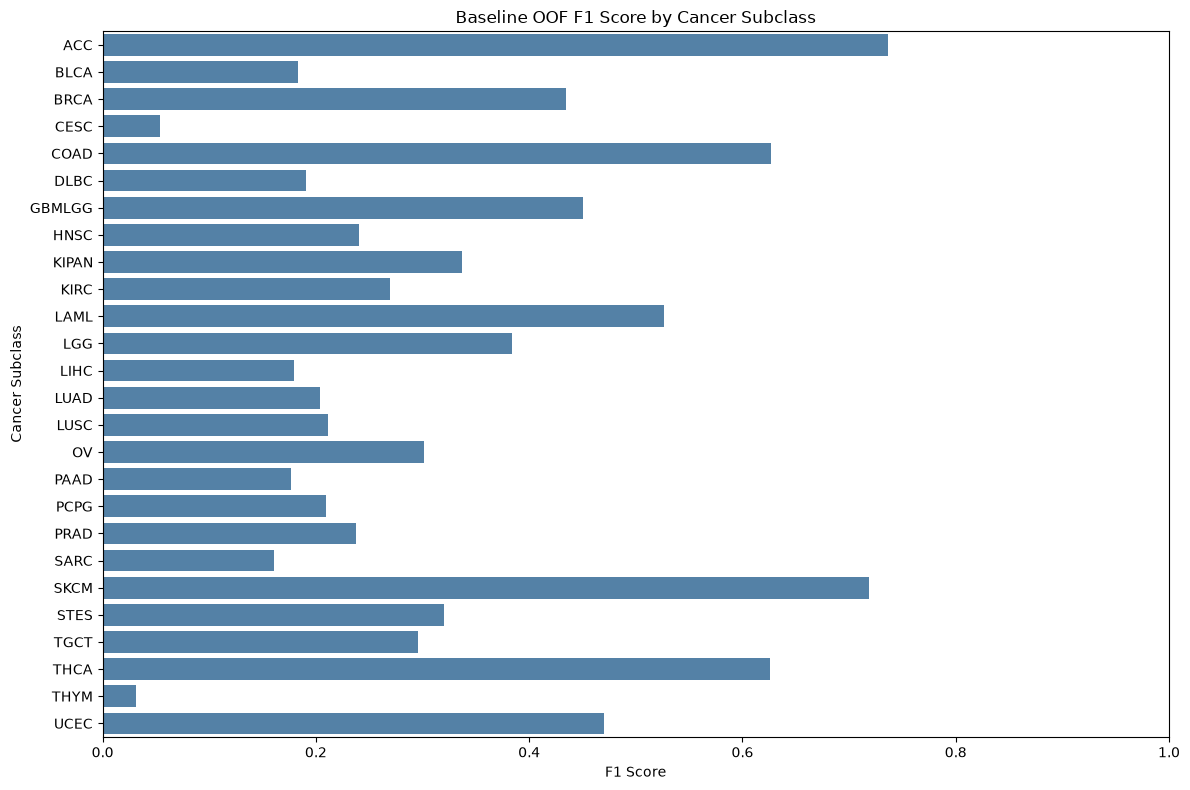

In [12]:
report = classification_report(
    y,
    oof_pred,
    output_dict=True,
    zero_division=0
)

class_f1 = pd.DataFrame(report).T

class_f1 = class_f1.loc[
    sorted(y.unique()),
    ["precision", "recall", "f1-score", "support"]
]

print("[암종별 OOF 성능]")
display(class_f1.sort_values("f1-score"))

# 암종별 F1 시각화
plt.figure(figsize=(12, 8))

sns.barplot(
    data=class_f1.reset_index(),
    x="f1-score",
    y="index",
    color="steelblue"
)

plt.title("Baseline OOF F1 Score by Cancer Subclass")
plt.xlabel("F1 Score")
plt.ylabel("Cancer Subclass")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

Step 30 — 클래스 가중치 최적화 실험

In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score
import pandas as pd
import numpy as np
import time

# 기존과 동일한 검증 방식
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

weight_options = {
    "Baseline_None": None,
    "Balanced": "balanced"
}

results = []
oof_predictions = {}

for experiment, weight in weight_options.items():

    print(f"\n===== {experiment} =====")

    fold_scores = []
    oof_pred_exp = np.empty(
        len(y),
        dtype=object
    )

    start_time = time.time()

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_binary, y, groups),
        start=1
    ):

        model = LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight=weight
        )

        model.fit(
            X_binary[train_idx],
            y.iloc[train_idx]
        )

        pred = model.predict(
            X_binary[valid_idx]
        )

        oof_pred_exp[valid_idx] = pred

        score = f1_score(
            y.iloc[valid_idx],
            pred,
            average="macro"
        )

        fold_scores.append(score)

        print(f"Fold {fold}: {score:.4f}")

    oof_predictions[experiment] = oof_pred_exp

    oof_f1 = f1_score(
        y,
        oof_pred_exp,
        average="macro"
    )

    results.append({
        "Experiment": experiment,
        "Mean_Macro_F1": np.mean(fold_scores),
        "Std_Macro_F1": np.std(fold_scores, ddof=1),
        "OOF_Macro_F1": oof_f1,
        "OOF_Accuracy": accuracy_score(y, oof_pred_exp),
        "Time_sec": round(time.time() - start_time, 2)
    })

comparison_df = pd.DataFrame(results)

print("\n[클래스 가중치 비교 결과]")
display(comparison_df.round(4))



===== Baseline_None =====
Fold 1: 0.3250
Fold 2: 0.3232
Fold 3: 0.3076
Fold 4: 0.3516
Fold 5: 0.3311

===== Balanced =====
Fold 1: 0.3463
Fold 2: 0.3493
Fold 3: 0.3385
Fold 4: 0.3691
Fold 5: 0.3571

[클래스 가중치 비교 결과]


,Experiment,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,OOF_Accuracy,Time_sec
0,Baseline_None,0.3277,0.0159,0.3298,0.3745,7.61
1,Balanced,0.3520,0.0116,0.3540,0.3709,6.92


3. 클래스별 F1 변화 확인

In [14]:
from sklearn.metrics import classification_report

class_comparison = pd.DataFrame(index=sorted(y.unique()))

for experiment, pred in oof_predictions.items():

    report = classification_report(
        y,
        pred,
        output_dict=True,
        zero_division=0
    )

    class_comparison[experiment] = [
        report[c]["f1-score"]
        for c in class_comparison.index
    ]

class_comparison["Difference"] = (
    class_comparison["Balanced"]
    - class_comparison["Baseline_None"]
)

print("[클래스별 F1 변화]")
display(
    class_comparison.sort_values(
        "Difference",
        ascending=False
    ).round(4)
)

[클래스별 F1 변화]


,Baseline_None,Balanced,Difference
LGG,0.3840,0.5368,0.1528
KIRC,0.2694,0.3566,0.0871
THYM,0.0317,0.1167,0.0850
ACC,0.7368,0.8095,0.0727
DLBC,0.1905,0.2609,0.0704
TGCT,0.2959,0.3529,0.0571
LUSC,0.2109,0.2534,0.0425
PCPG,0.2091,0.2512,0.0421
BRCA,0.4345,0.4755,0.0411
PAAD,0.1768,0.2119,0.0351


Step 31 — 환자별 변이 개수 특징 추가

In [15]:

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score
import pandas as pd
import numpy as np

# --------------------------------
# 1. 환자별 변이 개수
# --------------------------------

mutation_count_feature = np.asarray(
    X_binary.sum(axis=1)
).reshape(-1, 1)

log_mutation_count = np.log1p(
    mutation_count_feature
)

# --------------------------------
# 2. 교차검증
# --------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

experiments = {
    "Binary_Balanced": {
        "use_count": False,
        "weight": "balanced"
    },
    "Binary_Count_Balanced": {
        "use_count": True,
        "weight": "balanced"
    },
    "Binary_Count_None": {
        "use_count": True,
        "weight": None
    }
}

results = []
oof_count_predictions = {}

# --------------------------------
# 3. 실험
# --------------------------------

for exp_name, config in experiments.items():

    print(f"\n===== {exp_name} =====")

    oof_pred_exp = np.empty(len(y), dtype=object)
    fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_binary, y, groups), start=1
    ):

        X_tr = X_binary[train_idx]
        X_val = X_binary[valid_idx]

        if config["use_count"]:

            scaler = StandardScaler()

            count_tr = scaler.fit_transform(
                log_mutation_count[train_idx]
            )

            count_val = scaler.transform(
                log_mutation_count[valid_idx]
            )

            X_tr = hstack(
                [X_tr, csr_matrix(count_tr)],
                format="csr"
            )

            X_val = hstack(
                [X_val, csr_matrix(count_val)],
                format="csr"
            )

        model = LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight=config["weight"]
        )

        model.fit(
            X_tr,
            y.iloc[train_idx]
        )

        pred = model.predict(X_val)

        oof_pred_exp[valid_idx] = pred

        score = f1_score(
            y.iloc[valid_idx],
            pred,
            average="macro"
        )

        fold_scores.append(score)

        print(f"Fold {fold}: {score:.4f}")

    oof_count_predictions[exp_name] = oof_pred_exp

    results.append({
        "Experiment": exp_name,
        "Mean_Macro_F1": np.mean(fold_scores),
        "Std_Macro_F1": np.std(fold_scores, ddof=1),
        "OOF_Macro_F1": f1_score(
            y, oof_pred_exp, average="macro"
        ),
        "OOF_Accuracy": accuracy_score(y, oof_pred_exp)
    })

count_comparison_df = pd.DataFrame(results)

print("\n[변이 개수 특징 추가 비교]")
display(
    count_comparison_df.sort_values(
        "OOF_Macro_F1", ascending=False
    ).round(4)
)



===== Binary_Balanced =====
Fold 1: 0.3463
Fold 2: 0.3493
Fold 3: 0.3385
Fold 4: 0.3691
Fold 5: 0.3571

===== Binary_Count_Balanced =====
Fold 1: 0.3950
Fold 2: 0.3707
Fold 3: 0.3675
Fold 4: 0.3778
Fold 5: 0.3796

===== Binary_Count_None =====
Fold 1: 0.3489
Fold 2: 0.3431
Fold 3: 0.3317
Fold 4: 0.3616
Fold 5: 0.3492

[변이 개수 특징 추가 비교]


,Experiment,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,OOF_Accuracy
1,Binary_Count_Balanced,0.3781,0.0107,0.3817,0.3967
0,Binary_Balanced,0.3520,0.0116,0.3540,0.3709
2,Binary_Count_None,0.3469,0.0109,0.3456,0.3920


3. 클래스별 F1 변화 확인

[암종별 OOF 성능]


,precision,recall,f1-score,support
THYM,0.071429,0.020408,0.031746,98.0
CESC,0.086957,0.038710,0.053571,155.0
SARC,0.171429,0.151515,0.160858,198.0
PAAD,0.262295,0.133333,0.176796,120.0
LIHC,0.351852,0.120253,0.179245,158.0
BLCA,0.444444,0.115385,0.183206,104.0
DLBC,1.000000,0.105263,0.190476,38.0
LUAD,0.287129,0.157609,0.203509,184.0
PCPG,0.214286,0.204082,0.209059,147.0
LUSC,0.298969,0.162921,0.210909,178.0


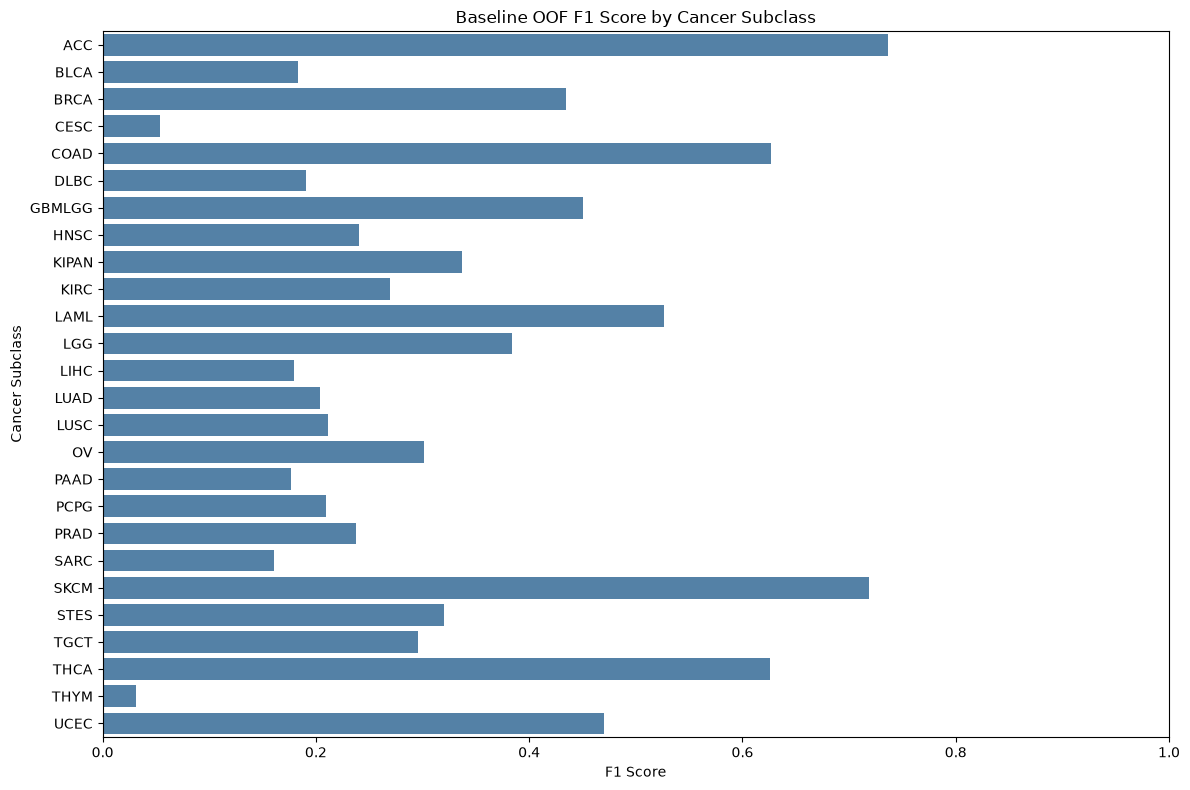

In [16]:
report = classification_report(
    y,
    oof_pred,
    output_dict=True,
    zero_division=0
)

class_f1 = pd.DataFrame(report).T

class_f1 = class_f1.loc[
    sorted(y.unique()),
    ["precision", "recall", "f1-score", "support"]
]

print("[암종별 OOF 성능]")
display(class_f1.sort_values("f1-score"))

# 암종별 F1 시각화
plt.figure(figsize=(12, 8))

sns.barplot(
    data=class_f1.reset_index(),
    x="f1-score",
    y="index",
    color="steelblue"
)

plt.title("Baseline OOF F1 Score by Cancer Subclass")
plt.xlabel("F1 Score")
plt.ylabel("Cancer Subclass")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

Step 32 — 암종별 F1 변화 확인

In [17]:

from sklearn.metrics import classification_report

class_count_comparison = pd.DataFrame(
    index=sorted(y.unique())
)

for exp_name, pred in oof_count_predictions.items():

    report = classification_report(
        y,
        pred,
        output_dict=True,
        zero_division=0
    )

    class_count_comparison[exp_name] = [
        report[c]["f1-score"]
        for c in class_count_comparison.index
    ]

class_count_comparison["Count_Effect"] = (
    class_count_comparison["Binary_Count_Balanced"]
    - class_count_comparison["Binary_Balanced"]
)

print("[변이 개수 추가에 따른 암종별 F1 변화]")

display(
    class_count_comparison.sort_values(
        "Count_Effect",
        ascending=False
    ).round(4)
)


[변이 개수 추가에 따른 암종별 F1 변화]


,Binary_Balanced,Binary_Count_Balanced,Binary_Count_None,Count_Effect
THYM,0.1167,0.2816,0.0187,0.1649
LAML,0.4451,0.5675,0.4874,0.1224
PRAD,0.2407,0.3025,0.2716,0.0618
LIHC,0.1909,0.2397,0.2177,0.0489
KIPAN,0.2827,0.3252,0.3590,0.0425
BLCA,0.2128,0.2533,0.2482,0.0406
GBMLGG,0.3533,0.3930,0.4642,0.0398
TGCT,0.3529,0.3918,0.3385,0.0389
PCPG,0.2512,0.2888,0.2490,0.0376
CESC,0.0815,0.1115,0.0741,0.0300


Step 33 — 변이 유형별 특징 추가 실험

2. Step 33-1 — 환자별 변이 유형 특징 생성

In [18]:

import re
import numpy as np
import pandas as pd
from functools import lru_cache

MUTATION_TYPES = [
    "Missense",
    "Synonymous",
    "Stop_gain",
    "Frameshift",
    "Other"
]

@lru_cache(maxsize=None)
def classify_token(token):
    if "fs" in token.lower():
        return "Frameshift"

    if re.fullmatch(r"[A-Z][0-9]+\*", token):
        return "Stop_gain"

    match = re.fullmatch(
        r"([A-Z])([0-9]+)([A-Z])", token
    )

    if match:
        return (
            "Synonymous"
            if match.group(1) == match.group(3)
            else "Missense"
        )

    return "Other"


@lru_cache(maxsize=None)
def mutation_type_counts(value):
    counts = np.zeros(5, dtype=np.int32)

    if value == "WT":
        return tuple(counts)

    for token in str(value).split():
        kind = classify_token(token)
        counts[MUTATION_TYPES.index(kind)] += 1

    return tuple(counts)


# WT가 아닌 셀만 처리
X_csc = X_binary.tocsc()

type_features = np.zeros(
    (len(X), len(MUTATION_TYPES)),
    dtype=np.int32
)

for j, gene in enumerate(gene_cols):
    start, end = X_csc.indptr[j:j+2]
    row_indices = X_csc.indices[start:end]

    values = X[gene].iloc[row_indices].to_numpy()

    for row_idx, value in zip(row_indices, values):
        type_features[row_idx] += mutation_type_counts(value)

type_feature_df = pd.DataFrame(
    type_features,
    columns=[f"{t}_Count" for t in MUTATION_TYPES]
)

print("[환자별 변이 유형 특징]")
display(type_feature_df.describe().round(2))

print("Shape:", type_feature_df.shape)


[환자별 변이 유형 특징]


,Missense_Count,Synonymous_Count,Stop_gain_Count,Frameshift_Count,Other_Count
count,6201.00,6201.00,6201.00,6201.0,6201.00
mean,26.57,10.79,2.14,1.6,0.05
std,121.61,58.73,11.21,5.9,0.47
min,0.00,0.00,0.00,0.0,0.00
25%,4.00,1.00,0.00,0.0,0.00
50%,9.00,3.00,1.00,1.0,0.00
75%,19.00,7.00,2.00,2.0,0.00
max,6002.00,3616.00,317.00,139.0,30.00


Shape: (6201, 5)


3. Step 33-2 — 기존 모델과 비교

In [19]:

from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score

# 총 변이 수 + 유형별 변이 수
count_features = np.column_stack([
    np.asarray(X_binary.sum(axis=1)).ravel(),
    type_features
])

log_count_features = np.log1p(count_features)

experiments = {
    "Binary_Count": 1,
    "Binary_Count_Types": 6
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

type_results = []
oof_type_predictions = {}

for name, n_features in experiments.items():

    print(f"\n===== {name} =====")

    fold_scores = []
    oof_pred_exp = np.empty(len(y), dtype=object)

    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_binary, y, groups),
        start=1
    ):

        scaler = StandardScaler()

        extra_tr = scaler.fit_transform(
            log_count_features[tr_idx, :n_features]
        )

        extra_val = scaler.transform(
            log_count_features[val_idx, :n_features]
        )

        X_tr = hstack([
            X_binary[tr_idx],
            csr_matrix(extra_tr)
        ], format="csr")

        X_val = hstack([
            X_binary[val_idx],
            csr_matrix(extra_val)
        ], format="csr")

        model = LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced"
        )

        model.fit(X_tr, y.iloc[tr_idx])
        pred = model.predict(X_val)

        oof_pred_exp[val_idx] = pred

        score = f1_score(
            y.iloc[val_idx],
            pred,
            average="macro"
        )

        fold_scores.append(score)
        print(f"Fold {fold}: {score:.4f}")

    oof_type_predictions[name] = oof_pred_exp

    type_results.append({
        "Experiment": name,
        "Mean_Macro_F1": np.mean(fold_scores),
        "Std_Macro_F1": np.std(fold_scores, ddof=1),
        "OOF_Macro_F1": f1_score(
            y, oof_pred_exp, average="macro"
        ),
        "Accuracy": accuracy_score(y, oof_pred_exp)
    })

type_comparison_df = pd.DataFrame(type_results)

print("\n[변이 유형 특징 실험 결과]")
display(type_comparison_df.round(4))



===== Binary_Count =====
Fold 1: 0.3950
Fold 2: 0.3707
Fold 3: 0.3675
Fold 4: 0.3778
Fold 5: 0.3796

===== Binary_Count_Types =====
Fold 1: 0.3968
Fold 2: 0.3763
Fold 3: 0.3882
Fold 4: 0.3998
Fold 5: 0.3975

[변이 유형 특징 실험 결과]


,Experiment,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,Accuracy
0,Binary_Count,0.3781,0.0107,0.3817,0.3967
1,Binary_Count_Types,0.3917,0.0097,0.3952,0.4114


4. Step 33-3 — 암종별 F1 비교

In [20]:

from sklearn.metrics import classification_report

class_type_comparison = pd.DataFrame(
    index=sorted(y.unique())
)

for name, pred in oof_type_predictions.items():
    report = classification_report(
        y, pred, output_dict=True, zero_division=0
    )

    class_type_comparison[name] = [
        report[c]["f1-score"]
        for c in class_type_comparison.index
    ]

class_type_comparison["Type_Effect"] = (
    class_type_comparison["Binary_Count_Types"]
    - class_type_comparison["Binary_Count"]
)

display(
    class_type_comparison.sort_values(
        "Type_Effect", ascending=False
    ).round(4)
)


,Binary_Count,Binary_Count_Types,Type_Effect
LUSC,0.2418,0.3851,0.1433
LUAD,0.2197,0.2809,0.0612
PCPG,0.2888,0.3492,0.0604
CESC,0.1115,0.1678,0.0563
TGCT,0.3918,0.4380,0.0461
BRCA,0.4760,0.5078,0.0318
KIPAN,0.3252,0.3472,0.0220
OV,0.3363,0.3583,0.0219
SARC,0.1924,0.2023,0.0099
LAML,0.5675,0.5743,0.0069


Step 34 — 특정 유전자 변이 정보 추가 실험

Step 34-1. 환자별 특정 변이 문자열 생성

In [21]:

from sklearn.feature_extraction.text import CountVectorizer
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler

# 환자별 구체적인 변이 문자열 생성
patient_mutations = [[] for _ in range(len(X))]

for gene in gene_cols:
    values = X[gene].to_numpy()

    mutated_rows = np.flatnonzero(values != "WT")

    for row_idx in mutated_rows:
        tokens = str(values[row_idx]).split()

        for token in set(tokens):
            patient_mutations[row_idx].append(
                f"{gene}_{token}"
            )

mutation_texts = [
    " ".join(tokens)
    for tokens in patient_mutations
]

print("환자 수:", len(mutation_texts))
print("첫 환자의 변이 특징 예시:")
print(mutation_texts[0][:300])


환자 수: 6201
첫 환자의 변이 특징 예시:
ABCC2_D623D ADCY2_F736C CD86_P117R EPHB4_R305S FOXC2_N23K GBF1_L192V GLMN_G592G GNAI1_K277K GOLGA4_A699T GPR182_L111L IRF2_I136M KIF1B_A219T LAS1L_E237* MYH11_A746D MYO1E_D465D NOS1_N1445D PPARD_T218T ROS1_G764G RTN3_E660Q SAMD9_E291A SMAD1_I382M SP110_V412A SPEG_P222R ST6GALNAC2_R104H TMEM176B_P17R


Step 34-2. 기존 모델과 특정 변이 모델 비교

In [22]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score

# 기존 총 변이 개수 + 유형별 개수
log_count_features = np.log1p(
    np.column_stack([
        np.asarray(X_binary.sum(axis=1)).ravel(),
        type_features
    ])
)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

experiments = {
    "Binary_Count_Types": False,
    "Binary_Count_Types_Specific": True
}

specific_results = []
oof_specific_predictions = {}

for exp_name, use_specific in experiments.items():

    print(f"\n===== {exp_name} =====")

    oof_pred_exp = np.empty(len(y), dtype=object)
    fold_scores = []
    feature_counts = []

    for fold, (tr_idx, val_idx) in enumerate(
        cv.split(X_binary, y, groups),
        start=1
    ):

        # 각 Fold의 학습 데이터에서만 Scaling
        scaler = StandardScaler()

        extra_tr = scaler.fit_transform(
            log_count_features[tr_idx]
        )

        extra_val = scaler.transform(
            log_count_features[val_idx]
        )

        X_tr = hstack([
            X_binary[tr_idx],
            csr_matrix(extra_tr)
        ], format="csr")

        X_val = hstack([
            X_binary[val_idx],
            csr_matrix(extra_val)
        ], format="csr")

        if use_specific:

            vectorizer = CountVectorizer(
                tokenizer=str.split,
                token_pattern=None,
                lowercase=False,
                binary=True,
                min_df=5
            )

            # 학습 Fold로만 어휘 학습
            specific_tr = vectorizer.fit_transform(
                [mutation_texts[i] for i in tr_idx]
            )

            # 검증 Fold는 transform만
            specific_val = vectorizer.transform(
                [mutation_texts[i] for i in val_idx]
            )

            feature_counts.append(specific_tr.shape[1])

            X_tr = hstack(
                [X_tr, specific_tr],
                format="csr"
            )

            X_val = hstack(
                [X_val, specific_val],
                format="csr"
            )

        model = LogisticRegression(
            C=1.0,
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced"
        )

        model.fit(X_tr, y.iloc[tr_idx])
        pred = model.predict(X_val)

        oof_pred_exp[val_idx] = pred

        score = f1_score(
            y.iloc[val_idx],
            pred,
            average="macro"
        )

        fold_scores.append(score)

        print(f"Fold {fold}: {score:.4f}")

    oof_specific_predictions[exp_name] = oof_pred_exp

    specific_results.append({
        "Experiment": exp_name,
        "Mean_Macro_F1": np.mean(fold_scores),
        "Std_Macro_F1": np.std(fold_scores, ddof=1),
        "OOF_Macro_F1": f1_score(
            y, oof_pred_exp, average="macro"
        ),
        "Accuracy": accuracy_score(y, oof_pred_exp),
        "Avg_Specific_Features": (
            np.mean(feature_counts)
            if feature_counts else 0
        )
    })

specific_comparison_df = pd.DataFrame(specific_results)

print("\n[특정 변이 특징 추가 결과]")
display(specific_comparison_df.round(4))



===== Binary_Count_Types =====
Fold 1: 0.3968
Fold 2: 0.3763
Fold 3: 0.3882
Fold 4: 0.3998
Fold 5: 0.3975

===== Binary_Count_Types_Specific =====
Fold 1: 0.4163
Fold 2: 0.3893
Fold 3: 0.3972
Fold 4: 0.4145
Fold 5: 0.4245

[특정 변이 특징 추가 결과]


,Experiment,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,Accuracy,Avg_Specific_Features
0,Binary_Count_Types,0.3917,0.0097,0.3952,0.4114,0.0
1,Binary_Count_Types_Specific,0.4083,0.0146,0.4109,0.4209,305.4


Step 35 — 특정 변이 특징 선택 기준 최적화

2. Step 35 실행 코드

In [23]:

from itertools import product
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

min_df_options = [2, 5, 10]
c_options = [0.1, 1.0, 3.0]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 동일한 분할 재사용
splits = list(cv.split(X_binary, y, groups))

results = []

for min_df in min_df_options:

    fold_data = []

    # 각 Fold의 학습 데이터로만 특징 생성
    for tr_idx, val_idx in splits:

        scaler = StandardScaler()

        extra_tr = scaler.fit_transform(
            log_count_features[tr_idx]
        )

        extra_val = scaler.transform(
            log_count_features[val_idx]
        )

        vectorizer = CountVectorizer(
            tokenizer=str.split,
            token_pattern=None,
            lowercase=False,
            binary=True,
            min_df=min_df
        )

        specific_tr = vectorizer.fit_transform(
            [mutation_texts[i] for i in tr_idx]
        )

        specific_val = vectorizer.transform(
            [mutation_texts[i] for i in val_idx]
        )

        X_tr = hstack([
            X_binary[tr_idx],
            csr_matrix(extra_tr),
            specific_tr
        ], format="csr")

        X_val = hstack([
            X_binary[val_idx],
            csr_matrix(extra_val),
            specific_val
        ], format="csr")

        fold_data.append(
            (X_tr, X_val, tr_idx, val_idx, specific_tr.shape[1])
        )

    for C in c_options:

        fold_scores = []
        oof_pred = np.empty(len(y), dtype=object)

        for fold, (
            X_tr, X_val, tr_idx, val_idx, n_features
        ) in enumerate(fold_data, start=1):

            model = LogisticRegression(
                C=C,
                max_iter=2000,
                solver="lbfgs",
                class_weight="balanced"
            )

            model.fit(
                X_tr,
                y.iloc[tr_idx]
            )

            pred = model.predict(X_val)

            oof_pred[val_idx] = pred

            score = f1_score(
                y.iloc[val_idx],
                pred,
                average="macro"
            )

            fold_scores.append(score)

        oof_score = f1_score(
            y,
            oof_pred,
            average="macro"
        )

        results.append({
            "min_df": min_df,
            "C": C,
            "Mean_Macro_F1": np.mean(fold_scores),
            "Std_Macro_F1": np.std(fold_scores, ddof=1),
            "OOF_Macro_F1": oof_score,
            "Avg_Specific_Features": np.mean(
                [d[4] for d in fold_data]
            )
        })

        print(
            f"min_df={min_df}, C={C} "
            f"-> OOF Macro F1={oof_score:.4f}"
        )

tuning_results = (
    pd.DataFrame(results)
    .sort_values("OOF_Macro_F1", ascending=False)
    .reset_index(drop=True)
)

print("\n[하이퍼파라미터 비교 결과]")
display(tuning_results.round(4))


min_df=2, C=0.1 -> OOF Macro F1=0.4252
min_df=2, C=1.0 -> OOF Macro F1=0.4148
min_df=2, C=3.0 -> OOF Macro F1=0.3908
min_df=5, C=0.1 -> OOF Macro F1=0.4276
min_df=5, C=1.0 -> OOF Macro F1=0.4109
min_df=5, C=3.0 -> OOF Macro F1=0.3926
min_df=10, C=0.1 -> OOF Macro F1=0.4232
min_df=10, C=1.0 -> OOF Macro F1=0.4088
min_df=10, C=3.0 -> OOF Macro F1=0.3881

[하이퍼파라미터 비교 결과]


,min_df,C,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,Avg_Specific_Features
0,5,0.1,0.4280,0.0070,0.4276,305.4
1,2,0.1,0.4253,0.0064,0.4252,11564.6
2,10,0.1,0.4234,0.0114,0.4232,78.0
3,2,1.0,0.4118,0.0095,0.4148,11564.6
4,5,1.0,0.4083,0.0146,0.4109,305.4
5,10,1.0,0.4058,0.0173,0.4088,78.0
6,5,3.0,0.3884,0.0141,0.3926,305.4
7,2,3.0,0.3865,0.0062,0.3908,11564.6
8,10,3.0,0.3841,0.0150,0.3881,78.0


3. 실험 결과 시각화

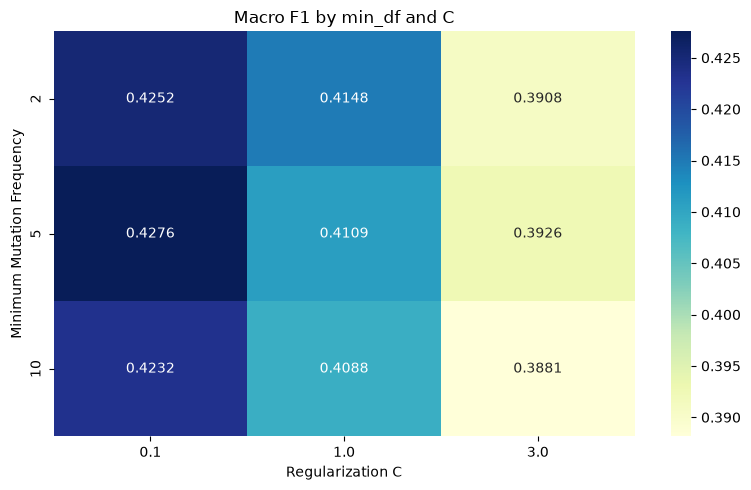

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot = tuning_results.pivot(
    index="min_df",
    columns="C",
    values="OOF_Macro_F1"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu"
)

plt.title("Macro F1 by min_df and C")
plt.xlabel("Regularization C")
plt.ylabel("Minimum Mutation Frequency")

plt.tight_layout()
plt.show()

Step 36 — 정규화 강도 세부 최적화

In [25]:

from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# 세부 실험 범위
c_values = [0.005, 0.01, 0.03, 0.05, 0.1, 0.2]

# 기존 Step 35와 동일한 5-Fold 분할
splits = list(cv.split(X_binary, y, groups))

# ---------------------------------------
# Fold별 특징 생성 (학습 데이터만 fit)
# ---------------------------------------
fold_data = []

for tr_idx, val_idx in splits:

    scaler = StandardScaler()

    extra_tr = scaler.fit_transform(
        log_count_features[tr_idx]
    )
    extra_val = scaler.transform(
        log_count_features[val_idx]
    )

    vectorizer = CountVectorizer(
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False,
        binary=True,
        min_df=5
    )

    specific_tr = vectorizer.fit_transform(
        [mutation_texts[i] for i in tr_idx]
    )
    specific_val = vectorizer.transform(
        [mutation_texts[i] for i in val_idx]
    )

    X_tr = hstack([
        X_binary[tr_idx],
        csr_matrix(extra_tr),
        specific_tr
    ], format="csr")

    X_val = hstack([
        X_binary[val_idx],
        csr_matrix(extra_val),
        specific_val
    ], format="csr")

    fold_data.append((X_tr, X_val, tr_idx, val_idx))


# ---------------------------------------
# C 값별 성능 비교
# ---------------------------------------
fine_tuning_results = []
fine_tuning_oof = {}

for C in c_values:

    fold_scores = []
    oof_pred = np.empty(len(y), dtype=object)

    for X_tr, X_val, tr_idx, val_idx in fold_data:

        model = LogisticRegression(
            C=C,
            max_iter=2000,
            solver="lbfgs",
            class_weight="balanced"
        )

        model.fit(X_tr, y.iloc[tr_idx])
        pred = model.predict(X_val)

        oof_pred[val_idx] = pred

        fold_scores.append(
            f1_score(
                y.iloc[val_idx],
                pred,
                average="macro"
            )
        )

    oof_score = f1_score(
        y, oof_pred, average="macro"
    )

    fine_tuning_oof[C] = oof_pred

    fine_tuning_results.append({
        "C": C,
        "Mean_Macro_F1": np.mean(fold_scores),
        "Std_Macro_F1": np.std(fold_scores, ddof=1),
        "OOF_Macro_F1": oof_score,
        "Fold_Scores": [round(s, 4) for s in fold_scores]
    })

    print(f"C={C}: OOF Macro F1={oof_score:.4f}")


fine_tuning_df = (
    pd.DataFrame(fine_tuning_results)
    .sort_values("OOF_Macro_F1", ascending=False)
    .reset_index(drop=True)
)

print("\n[C 세부 최적화 결과]")
display(fine_tuning_df)


C=0.005: OOF Macro F1=0.3520
C=0.01: OOF Macro F1=0.3784
C=0.03: OOF Macro F1=0.4105
C=0.05: OOF Macro F1=0.4197
C=0.1: OOF Macro F1=0.4276
C=0.2: OOF Macro F1=0.4321

[C 세부 최적화 결과]


,C,Mean_Macro_F1,Std_Macro_F1,OOF_Macro_F1,Fold_Scores
0,0.200,0.428848,0.012727,0.432100,"[0.4363, 0.4151, 0.4261, 0.42, 0.4467]"
1,0.100,0.427992,0.006993,0.427576,"[0.4228, 0.4239, 0.422, 0.4349, 0.4363]"
2,0.050,0.421056,0.012243,0.419725,"[0.4013, 0.4256, 0.4177, 0.4321, 0.4285]"
3,0.030,0.411359,0.009288,0.410464,"[0.3957, 0.4137, 0.419, 0.4174, 0.4109]"
4,0.010,0.378540,0.011833,0.378385,"[0.3657, 0.3977, 0.3794, 0.3748, 0.3752]"
5,0.005,0.352759,0.009002,0.351992,"[0.3386, 0.3634, 0.3541, 0.3524, 0.3554]"


3. C 값별 성능 시각화

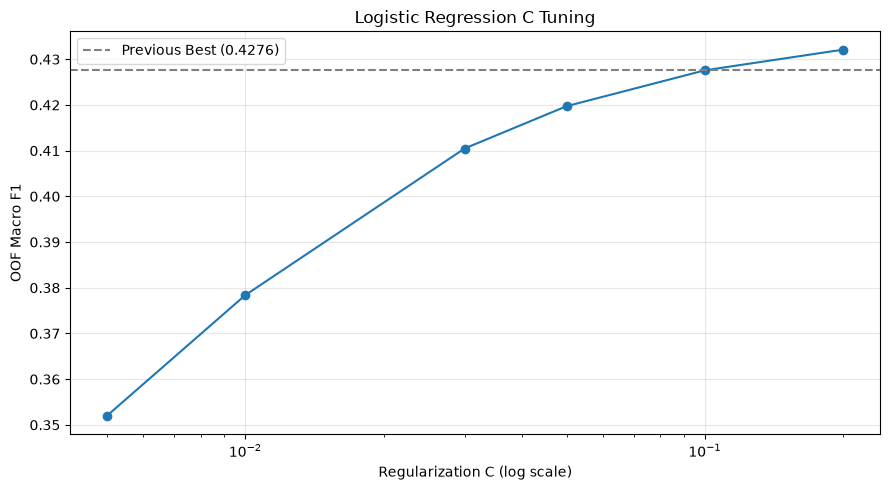

In [26]:
import matplotlib.pyplot as plt

plot_df = fine_tuning_df.sort_values("C")

plt.figure(figsize=(9, 5))
plt.plot(
    plot_df["C"],
    plot_df["OOF_Macro_F1"],
    marker="o"
)

plt.axhline(
    y=0.4276,
    color="gray",
    linestyle="--",
    label="Previous Best (0.4276)"
)

plt.xscale("log")
plt.title("Logistic Regression C Tuning")
plt.xlabel("Regularization C (log scale)")
plt.ylabel("OOF Macro F1")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Step 37 — LightGBM 모델과 성능 비교

In [27]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Step 37-2. LightGBM 5-Fold 학습

In [28]:

import lightgbm as lgb
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    accuracy_score
)

# OOF 예측 초기화
lgb_oof = np.empty(len(y), dtype=object)
lgb_fold_scores = []

for fold, (X_tr, X_val, tr_idx, val_idx) in enumerate(
    fold_data, start=1
):

    model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=26,
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        min_child_samples=30,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_tr,
        y.iloc[tr_idx]
    )

    pred = model.predict(X_val)
    lgb_oof[val_idx] = pred

    score = f1_score(
        y.iloc[val_idx],
        pred,
        average="macro"
    )

    lgb_fold_scores.append(score)

    print(f"Fold {fold}: Macro F1 = {score:.4f}")

print("\n[LightGBM 결과]")
print("Mean Macro F1:", round(np.mean(lgb_fold_scores), 4))
print("Std Macro F1:", round(np.std(lgb_fold_scores, ddof=1), 4))
print("OOF Macro F1:", round(f1_score(y, lgb_oof, average="macro"), 4))
print("OOF Accuracy:", round(accuracy_score(y, lgb_oof), 4))


Fold 1: Macro F1 = 0.4104
Fold 2: Macro F1 = 0.4329
Fold 3: Macro F1 = 0.4022
Fold 4: Macro F1 = 0.4080
Fold 5: Macro F1 = 0.4065

[LightGBM 결과]
Mean Macro F1: 0.412
Std Macro F1: 0.0121
OOF Macro F1: 0.4101
OOF Accuracy: 0.4248


Step 37-3. Logistic Regression과 비교

In [29]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression (C=0.1)",
        "Logistic Regression (C=0.2)",
        "LightGBM"
    ],
    "OOF_Macro_F1": [
        f1_score(y, fine_tuning_oof[0.1], average="macro"),
        f1_score(y, fine_tuning_oof[0.2], average="macro"),
        f1_score(y, lgb_oof, average="macro")
    ]
})

display(
    comparison.sort_values(
        "OOF_Macro_F1",
        ascending=False
    ).round(4)
)

,Model,OOF_Macro_F1
1,Logistic Regression (C=0.2),0.4321
0,Logistic Regression (C=0.1),0.4276
2,LightGBM,0.4101


. Step 38-1 — 모델 간 예측 비교

In [30]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report
)

# 기존 OOF 예측 불러오기
lr_pred = np.asarray(fine_tuning_oof[0.2])
lgb_pred = np.asarray(lgb_oof)
y_true = y.to_numpy()

# 정답 여부
lr_correct = lr_pred == y_true
lgb_correct = lgb_pred == y_true

# 네 가지 경우
comparison_cases = {
    "Both Correct": np.sum(lr_correct & lgb_correct),
    "LR Only": np.sum(lr_correct & ~lgb_correct),
    "LGBM Only": np.sum(~lr_correct & lgb_correct),
    "Both Wrong": np.sum(~lr_correct & ~lgb_correct)
}

comparison_cases_df = pd.DataFrame({
    "Case": comparison_cases.keys(),
    "Count": comparison_cases.values()
})

comparison_cases_df["Ratio (%)"] = (
    comparison_cases_df["Count"]
    / len(y_true) * 100
).round(2)

print("[모델별 정답 비교]")
display(comparison_cases_df)

print("\n[모델 간 예측 불일치율]")
print(
    f"{np.mean(lr_pred != lgb_pred) * 100:.2f}%"
)

print("\n[각 모델 Macro F1]")
print("Logistic Regression:",
      round(f1_score(y_true, lr_pred, average="macro"), 4))
print("LightGBM:",
      round(f1_score(y_true, lgb_pred, average="macro"), 4))


[모델별 정답 비교]


,Case,Count,Ratio (%)
0,Both Correct,2119,34.17
1,LR Only,561,9.05
2,LGBM Only,515,8.31
3,Both Wrong,3006,48.48



[모델 간 예측 불일치율]
37.88%

[각 모델 Macro F1]
Logistic Regression: 0.4321
LightGBM: 0.4101


3. Step 38-2 — 암종별 성능 비교

In [31]:

classes = sorted(y.unique())

lr_report = classification_report(
    y_true, lr_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)

lgb_report = classification_report(
    y_true, lgb_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)

model_class_comparison = pd.DataFrame({
    "SUBCLASS": classes,
    "LR_F1": [
        lr_report[c]["f1-score"] for c in classes
    ],
    "LightGBM_F1": [
        lgb_report[c]["f1-score"] for c in classes
    ]
})

model_class_comparison["LGBM_Advantage"] = (
    model_class_comparison["LightGBM_F1"]
    - model_class_comparison["LR_F1"]
)

print("[암종별 모델 성능 차이]")

display(
    model_class_comparison.sort_values(
        "LGBM_Advantage",
        ascending=False
    ).round(4)
)


[암종별 모델 성능 차이]


,SUBCLASS,LR_F1,LightGBM_F1,LGBM_Advantage
25,UCEC,0.5441,0.6161,0.0720
21,STES,0.3910,0.4505,0.0595
1,BLCA,0.3312,0.3871,0.0559
9,KIRC,0.4032,0.4415,0.0383
4,COAD,0.6624,0.6951,0.0326
14,LUSC,0.4582,0.4804,0.0222
12,LIHC,0.2710,0.2891,0.0181
11,LGG,0.5699,0.5836,0.0137
2,BRCA,0.5146,0.5204,0.0058
7,HNSC,0.2977,0.2989,0.0012


Step 38-3 — 모델 간 정답 비교 시각화

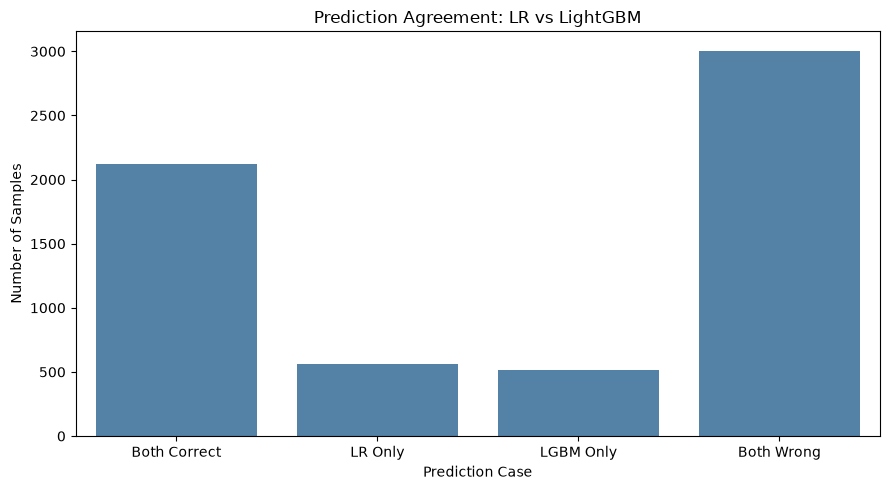

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_cases_df,
    x="Case",
    y="Count",
    color="steelblue"
)

plt.title("Prediction Agreement: LR vs LightGBM")
plt.xlabel("Prediction Case")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

Step 39 — Logistic Regression + LightGBM 앙상블 실험

In [33]:

import numpy as np
import pandas as pd
import lightgbm as lgb

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# 전체 클래스 순서 통일
classes = np.array(sorted(y.unique()))
n_classes = len(classes)

lr_oof_proba = np.zeros((len(y), n_classes))
lgb_oof_proba = np.zeros((len(y), n_classes))

for fold, (X_tr, X_val, tr_idx, val_idx) in enumerate(
    fold_data, start=1
):

    # Logistic Regression
    lr_model = LogisticRegression(
        C=0.2,
        max_iter=2000,
        solver="lbfgs",
        class_weight="balanced"
    )

    lr_model.fit(X_tr, y.iloc[tr_idx])

    # LightGBM
    lgb_model = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=26,
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=30,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    lgb_model.fit(X_tr, y.iloc[tr_idx])

    # 클래스 순서 정렬
    lr_order = [
        np.where(lr_model.classes_ == c)[0][0]
        for c in classes
    ]

    lgb_order = [
        np.where(lgb_model.classes_ == c)[0][0]
        for c in classes
    ]

    lr_oof_proba[val_idx] = (
        lr_model.predict_proba(X_val)[:, lr_order]
    )

    lgb_oof_proba[val_idx] = (
        lgb_model.predict_proba(X_val)[:, lgb_order]
    )

    print(f"Fold {fold} 완료")

print("\nOOF 확률 생성 완료")
print("LR:", lr_oof_proba.shape)
print("LGBM:", lgb_oof_proba.shape)


Fold 1 완료
Fold 2 완료
Fold 3 완료
Fold 4 완료
Fold 5 완료

OOF 확률 생성 완료
LR: (6201, 26)
LGBM: (6201, 26)


3. Step 39-2 — 가중치별 성능 비교

In [34]:

from sklearn.metrics import f1_score, accuracy_score

weights = [0.0, 0.25, 0.5, 0.75, 1.0]

ensemble_results = []
ensemble_predictions = {}

for w in weights:

    combined_proba = (
        w * lr_oof_proba
        + (1 - w) * lgb_oof_proba
    )

    pred = classes[np.argmax(combined_proba, axis=1)]

    ensemble_predictions[w] = pred

    macro_f1 = f1_score(
        y, pred, average="macro"
    )

    accuracy = accuracy_score(y, pred)

    ensemble_results.append({
        "LR_Weight": w,
        "LGBM_Weight": 1 - w,
        "OOF_Macro_F1": macro_f1,
        "OOF_Accuracy": accuracy
    })

ensemble_df = (
    pd.DataFrame(ensemble_results)
    .sort_values("OOF_Macro_F1", ascending=False)
)

print("[Soft Voting 앙상블 결과]")
display(ensemble_df.round(4))


[Soft Voting 앙상블 결과]


,LR_Weight,LGBM_Weight,OOF_Macro_F1,OOF_Accuracy
3,0.75,0.25,0.4395,0.4423
2,0.50,0.50,0.4337,0.4428
4,1.00,0.00,0.4321,0.4322
1,0.25,0.75,0.4214,0.4343
0,0.00,1.00,0.4101,0.4248


4. Step 39-3 — 앙상블 성능 시각화

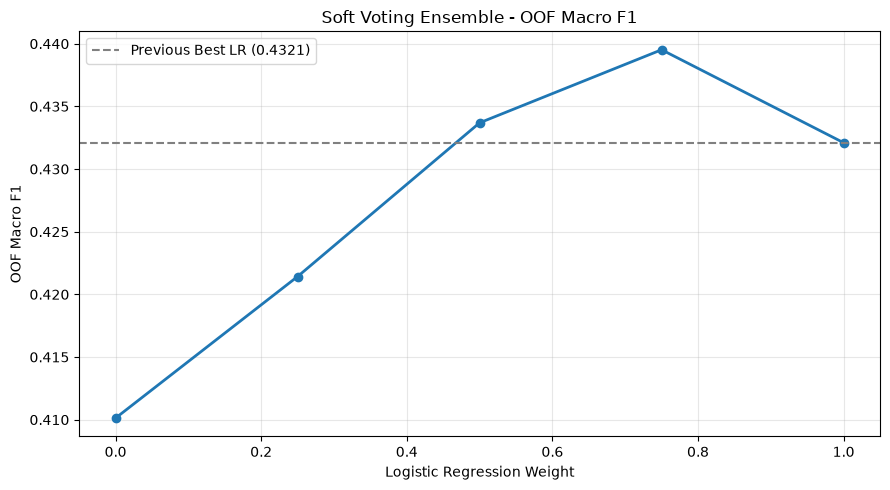

In [35]:

import matplotlib.pyplot as plt

plot_df = ensemble_df.sort_values("LR_Weight")

plt.figure(figsize=(9, 5))

plt.plot(
    plot_df["LR_Weight"],
    plot_df["OOF_Macro_F1"],
    marker="o",
    linewidth=2
)

plt.axhline(
    y=0.4321,
    color="gray",
    linestyle="--",
    label="Previous Best LR (0.4321)"
)

plt.title("Soft Voting Ensemble - OOF Macro F1")
plt.xlabel("Logistic Regression Weight")
plt.ylabel("OOF Macro F1")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Step 40 — 앙상블 안정성 및 암종별 성능 검증

1. Step 40-1 — Fold별 앙상블 성능

In [36]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

# 기존과 동일한 분할
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(cv.split(X_binary, y, groups))

# 클래스 순서
classes = np.array(sorted(y.unique()))

# 모델별 예측
lr_pred = classes[np.argmax(lr_oof_proba, axis=1)]

lgb_pred = classes[np.argmax(lgb_oof_proba, axis=1)]

# 75:25 Soft Voting
ensemble_proba = (
    0.75 * lr_oof_proba
    + 0.25 * lgb_oof_proba
)

ensemble_pred = classes[
    np.argmax(ensemble_proba, axis=1)
]

fold_results = []

for fold, (_, val_idx) in enumerate(splits, start=1):

    y_val = y.iloc[val_idx]

    lr_f1 = f1_score(
        y_val, lr_pred[val_idx], average="macro"
    )

    lgb_f1 = f1_score(
        y_val, lgb_pred[val_idx], average="macro"
    )

    ens_f1 = f1_score(
        y_val, ensemble_pred[val_idx], average="macro"
    )

    fold_results.append({
        "Fold": fold,
        "LR_F1": lr_f1,
        "LGBM_F1": lgb_f1,
        "Ensemble_F1": ens_f1,
        "Gain_vs_LR": ens_f1 - lr_f1
    })

fold_ensemble_df = pd.DataFrame(fold_results)

print("[Fold별 앙상블 성능]")
display(fold_ensemble_df.round(4))

print("\n[전체 OOF Macro F1]")
print("LR:", round(f1_score(y, lr_pred, average="macro"), 4))
print("LGBM:", round(f1_score(y, lgb_pred, average="macro"), 4))
print("Ensemble:", round(f1_score(y, ensemble_pred, average="macro"), 4))


[Fold별 앙상블 성능]


,Fold,LR_F1,LGBM_F1,Ensemble_F1,Gain_vs_LR
0,1,0.4363,0.4104,0.4472,0.0109
1,2,0.4151,0.4329,0.4291,0.0140
2,3,0.4261,0.4022,0.4328,0.0067
3,4,0.4200,0.4080,0.4348,0.0148
4,5,0.4467,0.4065,0.4407,-0.0060



[전체 OOF Macro F1]
LR: 0.4321
LGBM: 0.4101
Ensemble: 0.4395


2. Step 40-2 — 암종별 F1 변화 확인

In [37]:

from sklearn.metrics import classification_report

class_reports = {}

for name, pred in {
    "LR": lr_pred,
    "LightGBM": lgb_pred,
    "Ensemble": ensemble_pred
}.items():

    report = classification_report(
        y,
        pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    class_reports[name] = [
        report[c]["f1-score"]
        for c in classes
    ]

ensemble_class_df = pd.DataFrame(
    class_reports,
    index=classes
)

ensemble_class_df["Gain_vs_LR"] = (
    ensemble_class_df["Ensemble"]
    - ensemble_class_df["LR"]
)

print("[암종별 앙상블 성능 변화]")

display(
    ensemble_class_df.sort_values(
        "Gain_vs_LR", ascending=False
    ).round(4)
)


[암종별 앙상블 성능 변화]


,LR,LightGBM,Ensemble,Gain_vs_LR
UCEC,0.5441,0.6161,0.5771,0.0330
STES,0.3910,0.4505,0.4232,0.0322
LIHC,0.2710,0.2891,0.2981,0.0272
KIRC,0.4032,0.4415,0.4275,0.0243
BLCA,0.3312,0.3871,0.3522,0.0210
BRCA,0.5146,0.5204,0.5318,0.0173
CESC,0.2071,0.2018,0.2222,0.0151
OV,0.3732,0.3424,0.3883,0.0151
COAD,0.6624,0.6951,0.6752,0.0127
PCPG,0.3503,0.3130,0.3620,0.0117


Step 41 — XGBoost 모델 성능 비교

In [38]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB 1.3 MB/s eta 0:00:39
   ---------------------------------------- 0.2/48.9 MB 1.7 MB/s eta 0:00:28
   ---------------------------------------- 0.6/48.9 MB 4.2 MB/s eta 0:00:12
    --------------------------------------- 1.0/48.9 MB 5.4 MB/s eta 0:00:09
   - -------------------------------------- 1.4/48.9 MB 6.1 MB/s eta 0:00:08
   - -------------------------------------- 1.5/48.9 MB 5.7 MB/s eta 0:00:09
   - -------------------------------------- 2.0/48.9 MB 6.2 MB/s eta 0:00:08
   - -------------------------------------- 2.4/48.9 MB 6.7 MB/s eta 0:00:07
   -- ------------------------------------- 2.8/48.9 MB 6.9 MB/s eta 0:00:07
   -- ------------------------------------- 3.2/48.9 MB 7.1 MB/s eta 0:00:07
   --- ------------------------------------ 3.7/48.9 MB 7.4 MB/s eta 0:00:07
   --- ------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Step 41-2. XGBoost 5-Fold 학습

In [39]:

import xgboost as xgb
import numpy as np
import pandas as pd
import time

from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

# 기존 Fold별 전처리 데이터 재사용
# fold_data: (X_tr, X_val, tr_idx, val_idx)

classes = np.array(sorted(y.unique()))
class_to_idx = {
    label: idx for idx, label in enumerate(classes)
}

# XGBoost용 정수 레이블
y_encoded = np.array([
    class_to_idx[label] for label in y
])

xgb_oof_proba = np.zeros(
    (len(y), len(classes)),
    dtype=np.float64
)

xgb_fold_scores = []

start_time = time.time()

for fold, (X_tr, X_val, tr_idx, val_idx) in enumerate(
    fold_data, start=1
):

    y_tr = y_encoded[tr_idx]
    y_val = y_encoded[val_idx]

    # 학습 Fold에서만 클래스 가중치 계산
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=len(classes),
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        reg_alpha=0.5,
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )

    model.fit(
        X_tr,
        y_tr,
        sample_weight=sample_weights
    )

    proba = model.predict_proba(X_val)
    xgb_oof_proba[val_idx] = proba

    pred = np.argmax(proba, axis=1)

    score = f1_score(
        y_val,
        pred,
        average="macro",
        labels=np.arange(len(classes)),
        zero_division=0
    )

    xgb_fold_scores.append(score)

    print(f"Fold {fold}: Macro F1 = {score:.4f}")

# 전체 OOF 예측
xgb_pred = classes[
    np.argmax(xgb_oof_proba, axis=1)
]

print("\n[XGBoost 결과]")
print("Mean Macro F1:",
      round(np.mean(xgb_fold_scores), 4))

print("Std Macro F1:",
      round(np.std(xgb_fold_scores, ddof=1), 4))

print("OOF Macro F1:",
      round(f1_score(y, xgb_pred, average="macro"), 4))

print("OOF Accuracy:",
      round(accuracy_score(y, xgb_pred), 4))

print("Total Time (sec):",
      round(time.time() - start_time, 2))


Fold 1: Macro F1 = 0.4145
Fold 2: Macro F1 = 0.4178
Fold 3: Macro F1 = 0.4195
Fold 4: Macro F1 = 0.4086
Fold 5: Macro F1 = 0.4281

[XGBoost 결과]
Mean Macro F1: 0.4177
Std Macro F1: 0.0072
OOF Macro F1: 0.4196
OOF Accuracy: 0.417
Total Time (sec): 115.45


2. Step 41-3 — 세 모델 비교

In [40]:

# 기존 모델 예측
lr_pred = classes[
    np.argmax(lr_oof_proba, axis=1)
]

lgb_pred = classes[
    np.argmax(lgb_oof_proba, axis=1)
]

# 기존 75:25 앙상블
ensemble_pred = classes[
    np.argmax(
        0.75 * lr_oof_proba
        + 0.25 * lgb_oof_proba,
        axis=1
    )
]

# 모델별 성능
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LightGBM",
        "XGBoost",
        "LR + LightGBM Ensemble"
    ],
    "OOF_Macro_F1": [
        f1_score(y, lr_pred, average="macro"),
        f1_score(y, lgb_pred, average="macro"),
        f1_score(y, xgb_pred, average="macro"),
        f1_score(y, ensemble_pred, average="macro")
    ],
    "Accuracy": [
        accuracy_score(y, lr_pred),
        accuracy_score(y, lgb_pred),
        accuracy_score(y, xgb_pred),
        accuracy_score(y, ensemble_pred)
    ]
})

display(
    model_comparison.sort_values(
        "OOF_Macro_F1",
        ascending=False
    ).round(4)
)

# XGBoost만 맞힌 환자 수
lr_correct = lr_pred == y.to_numpy()
lgb_correct = lgb_pred == y.to_numpy()
xgb_correct = xgb_pred == y.to_numpy()

print("\n[XGBoost의 추가 기여 가능성]")
print(
    "LR과 LGBM은 틀렸지만 XGBoost만 맞힌 환자:",
    np.sum(~lr_correct & ~lgb_correct & xgb_correct)
)

print(
    "LR과 XGBoost의 예측 불일치율:",
    f"{np.mean(lr_pred != xgb_pred) * 100:.2f}%"
)


,Model,OOF_Macro_F1,Accuracy
3,LR + LightGBM Ensemble,0.4395,0.4423
0,Logistic Regression,0.4321,0.4322
2,XGBoost,0.4196,0.4170
1,LightGBM,0.4101,0.4248



[XGBoost의 추가 기여 가능성]
LR과 LGBM은 틀렸지만 XGBoost만 맞힌 환자: 144
LR과 XGBoost의 예측 불일치율: 38.72%


Step 42 — 3개 모델 Soft Voting 앙상블

2. Step 42-1 — 세 모델의 예측 확률 결합

In [41]:

import numpy as np
import pandas as pd

from sklearn.metrics import f1_score, accuracy_score

# ========================================
# 1. 클래스 순서 및 OOF 확률 확인
# ========================================

classes = np.array(sorted(y.unique()))
n_samples = len(y)
n_classes = len(classes)

assert lr_oof_proba.shape == (n_samples, n_classes)
assert lgb_oof_proba.shape == (n_samples, n_classes)
assert xgb_oof_proba.shape == (n_samples, n_classes)

# 세 모델은 동일한 5-Fold 분할과 클래스 순서를
# 사용하여 생성한 OOF 확률이어야 함

for name, proba in {
    "LR": lr_oof_proba,
    "LightGBM": lgb_oof_proba,
    "XGBoost": xgb_oof_proba
}.items():
    assert np.isfinite(proba).all()
    assert np.allclose(proba.sum(axis=1), 1, atol=1e-5)

print("OOF 확률 행렬 확인 완료")


# ========================================
# 2. 가중치 조합
# ========================================

weight_configs = {
    "LR_only": (1.0, 0.0, 0.0),
    "Previous_Best": (0.75, 0.25, 0.0),
    "3Model_A": (0.675, 0.225, 0.10),
    "3Model_B": (0.60, 0.20, 0.20),
    "3Model_C": (0.525, 0.175, 0.30),
    "LR_XGB_A": (0.75, 0.0, 0.25),
    "LR_XGB_B": (0.50, 0.0, 0.50)
}

ensemble3_results = []
ensemble3_predictions = {}

# ========================================
# 3. 앙상블 성능 평가
# ========================================

for name, (w_lr, w_lgb, w_xgb) in weight_configs.items():

    proba = (
        w_lr * lr_oof_proba
        + w_lgb * lgb_oof_proba
        + w_xgb * xgb_oof_proba
    )

    pred = classes[np.argmax(proba, axis=1)]
    ensemble3_predictions[name] = pred

    macro_f1 = f1_score(
        y, pred,
        average="macro",
        labels=classes,
        zero_division=0
    )

    accuracy = accuracy_score(y, pred)

    ensemble3_results.append({
        "Experiment": name,
        "LR_Weight": w_lr,
        "LGBM_Weight": w_lgb,
        "XGB_Weight": w_xgb,
        "OOF_Macro_F1": macro_f1,
        "OOF_Accuracy": accuracy
    })

ensemble3_df = (
    pd.DataFrame(ensemble3_results)
    .sort_values("OOF_Macro_F1", ascending=False)
    .reset_index(drop=True)
)

print("[3개 모델 앙상블 비교]")
display(ensemble3_df.round(4))

print("\n기존 최고 점수: 0.4395")
print(
    "이번 실험 최고 점수:",
    round(ensemble3_df.iloc[0]["OOF_Macro_F1"], 4)
)


OOF 확률 행렬 확인 완료
[3개 모델 앙상블 비교]


,Experiment,LR_Weight,LGBM_Weight,XGB_Weight,OOF_Macro_F1,OOF_Accuracy
0,3Model_C,0.525,0.175,0.30,0.4493,0.4438
1,LR_XGB_A,0.750,0.000,0.25,0.4445,0.4398
2,3Model_B,0.600,0.200,0.20,0.4444,0.4443
3,3Model_A,0.675,0.225,0.10,0.4440,0.4459
4,LR_XGB_B,0.500,0.000,0.50,0.4424,0.4370
5,Previous_Best,0.750,0.250,0.00,0.4395,0.4423
6,LR_only,1.000,0.000,0.00,0.4321,0.4322



기존 최고 점수: 0.4395
이번 실험 최고 점수: 0.4493


3. Step 42-2 — Fold별 안정성 확인

In [45]:
best_name = ensemble3_df.iloc[0]["Experiment"]

print("최고 앙상블:", best_name)

최고 앙상블: 3Model_C


In [46]:

from sklearn.metrics import classification_report

previous_pred = ensemble3_predictions["Previous_Best"]
best_pred = ensemble3_predictions[best_name]

reports = {}

for name, pred in {
    "Previous": previous_pred,
    "Best": best_pred
}.items():

    report = classification_report(
        y, pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    reports[name] = [
        report[c]["f1-score"]
        for c in classes
    ]

class_ensemble3_df = pd.DataFrame(
    reports,
    index=classes
)

class_ensemble3_df["Difference"] = (
    class_ensemble3_df["Best"]
    - class_ensemble3_df["Previous"]
)

print("[암종별 앙상블 성능 비교]")
display(
    class_ensemble3_df.sort_values(
        "Difference", ascending=False
    ).round(4)
)


[암종별 앙상블 성능 비교]


,Previous,Best,Difference
DLBC,0.3774,0.5424,0.1650
BLCA,0.3522,0.4348,0.0826
UCEC,0.5771,0.6214,0.0442
LUSC,0.4496,0.4925,0.0429
LIHC,0.2981,0.3290,0.0309
LUAD,0.3488,0.3699,0.0211
COAD,0.6752,0.6957,0.0205
STES,0.4232,0.4372,0.0141
HNSC,0.3002,0.3095,0.0092
THYM,0.2849,0.2923,0.0073


In [47]:

import pandas as pd
import numpy as np

from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import StratifiedGroupKFold

# 최고 앙상블 선택
best_name = ensemble3_df.iloc[0]["Experiment"]

print("최고 앙상블:", best_name)

# 기존 모델과 최고 모델의 OOF 예측
previous_pred = ensemble3_predictions["Previous_Best"]
best_pred = ensemble3_predictions[best_name]

# ======================================
# 1. Fold별 성능 비교
# ======================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(cv.split(X_binary, y, groups))

fold_comparison = []

for fold, (_, val_idx) in enumerate(splits, start=1):

    y_val = y.iloc[val_idx]

    previous_f1 = f1_score(
        y_val,
        previous_pred[val_idx],
        average="macro",
        zero_division=0
    )

    best_f1 = f1_score(
        y_val,
        best_pred[val_idx],
        average="macro",
        zero_division=0
    )

    fold_comparison.append({
        "Fold": fold,
        "Previous_F1": previous_f1,
        "Best_F1": best_f1,
        "Difference": best_f1 - previous_f1
    })

fold_comparison_df = pd.DataFrame(fold_comparison)

print("\n[Fold별 성능 비교]")
display(fold_comparison_df.round(4))


# ======================================
# 2. 암종별 성능 비교
# ======================================

classes = np.array(sorted(y.unique()))

previous_report = classification_report(
    y,
    previous_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)

best_report = classification_report(
    y,
    best_pred,
    labels=classes,
    output_dict=True,
    zero_division=0
)

class_ensemble3_df = pd.DataFrame({
    "SUBCLASS": classes,
    "Previous_F1": [
        previous_report[c]["f1-score"]
        for c in classes
    ],
    "Best_F1": [
        best_report[c]["f1-score"]
        for c in classes
    ]
})

class_ensemble3_df["Difference"] = (
    class_ensemble3_df["Best_F1"]
    - class_ensemble3_df["Previous_F1"]
)

print("\n[암종별 성능 비교]")

display(
    class_ensemble3_df.sort_values(
        "Difference",
        ascending=False
    ).round(4)
)


최고 앙상블: 3Model_C

[Fold별 성능 비교]


,Fold,Previous_F1,Best_F1,Difference
0,1,0.4472,0.4367,-0.0105
1,2,0.4291,0.4437,0.0146
2,3,0.4328,0.4547,0.0219
3,4,0.4348,0.4452,0.0104
4,5,0.4407,0.4545,0.0139



[암종별 성능 비교]


,SUBCLASS,Previous_F1,Best_F1,Difference
5,DLBC,0.3774,0.5424,0.1650
1,BLCA,0.3522,0.4348,0.0826
25,UCEC,0.5771,0.6214,0.0442
14,LUSC,0.4496,0.4925,0.0429
12,LIHC,0.2981,0.3290,0.0309
13,LUAD,0.3488,0.3699,0.0211
4,COAD,0.6752,0.6957,0.0205
21,STES,0.4232,0.4372,0.0141
7,HNSC,0.3002,0.3095,0.0092
24,THYM,0.2849,0.2923,0.0073


Step 43 — 앙상블 가중치 안정성 분석

Step 43-1. XGBoost 가중치별 성능

In [48]:

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# XGBoost 가중치 범위
xgb_weights = np.arange(0, 0.51, 0.05)

# 기존 LR : LightGBM = 3 : 1 유지
results = []

for w_xgb in xgb_weights:

    remaining = 1 - w_xgb

    w_lr = remaining * 0.75
    w_lgb = remaining * 0.25

    combined = (
        w_lr * lr_oof_proba
        + w_lgb * lgb_oof_proba
        + w_xgb * xgb_oof_proba
    )

    pred = classes[np.argmax(combined, axis=1)]

    score = f1_score(
        y, pred, average="macro"
    )

    results.append({
        "LR": w_lr,
        "LightGBM": w_lgb,
        "XGBoost": w_xgb,
        "OOF_Macro_F1": score
    })

weight_stability_df = pd.DataFrame(results)

display(weight_stability_df.round(4))


,LR,LightGBM,XGBoost,OOF_Macro_F1
0,0.7500,0.2500,0.00,0.4395
1,0.7125,0.2375,0.05,0.4433
2,0.6750,0.2250,0.10,0.4440
3,0.6375,0.2125,0.15,0.4440
4,0.6000,0.2000,0.20,0.4444
5,0.5625,0.1875,0.25,0.4455
6,0.5250,0.1750,0.30,0.4493
7,0.4875,0.1625,0.35,0.4482
8,0.4500,0.1500,0.40,0.4469
9,0.4125,0.1375,0.45,0.4466


Step 43-2. 가중치 안정성 시각화

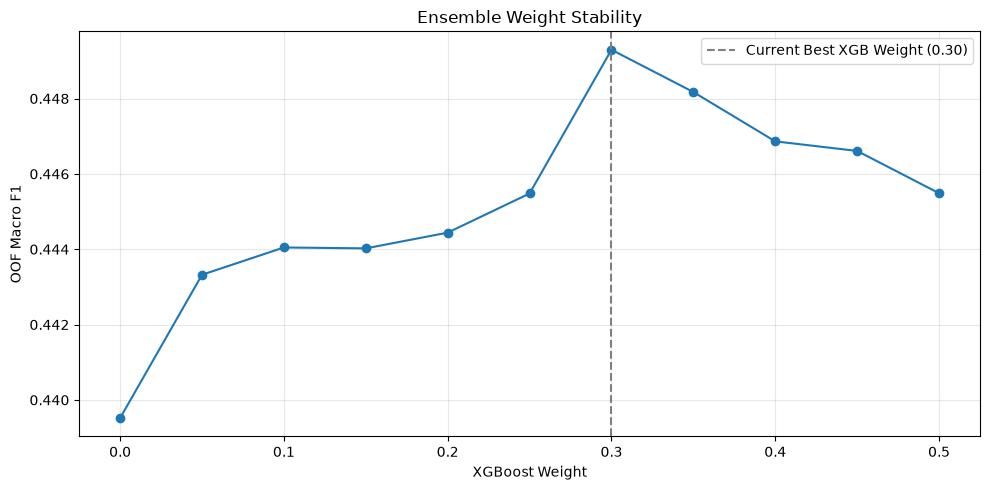

In [49]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    weight_stability_df["XGBoost"],
    weight_stability_df["OOF_Macro_F1"],
    marker="o"
)

plt.axvline(
    0.30,
    linestyle="--",
    color="gray",
    label="Current Best XGB Weight (0.30)"
)

plt.title("Ensemble Weight Stability")
plt.xlabel("XGBoost Weight")
plt.ylabel("OOF Macro F1")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Step 43-3. Fold별 가중치 민감도 분석

In [50]:

from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(cv.split(X_binary, y, groups))

fold_weight_results = []

for w_xgb in xgb_weights:

    remaining = 1 - w_xgb

    combined = (
        remaining * 0.75 * lr_oof_proba
        + remaining * 0.25 * lgb_oof_proba
        + w_xgb * xgb_oof_proba
    )

    pred = classes[np.argmax(combined, axis=1)]

    row = {"XGB_Weight": round(float(w_xgb), 2)}

    for fold, (_, val_idx) in enumerate(splits, start=1):

        row[f"Fold_{fold}"] = f1_score(
            y.iloc[val_idx],
            pred[val_idx],
            average="macro",
            zero_division=0
        )

    fold_weight_results.append(row)

fold_weight_df = pd.DataFrame(fold_weight_results)

print("[Fold별 가중치 민감도]")
display(fold_weight_df.round(4))


[Fold별 가중치 민감도]


,XGB_Weight,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,0.00,0.4472,0.4291,0.4328,0.4348,0.4407
1,0.05,0.4526,0.4349,0.4352,0.4396,0.4432
2,0.10,0.4510,0.4392,0.4382,0.4423,0.4397
3,0.15,0.4493,0.4368,0.4403,0.4436,0.4401
4,0.20,0.4431,0.4349,0.4540,0.4431,0.4359
5,0.25,0.4412,0.4428,0.4574,0.4369,0.4382
6,0.30,0.4367,0.4437,0.4547,0.4452,0.4545
7,0.35,0.4372,0.4428,0.4578,0.4394,0.4529
8,0.40,0.4378,0.4399,0.4550,0.4385,0.4524
9,0.45,0.4354,0.4416,0.4530,0.4378,0.4536


Step 44 — Nested Cross-Validation 검증 환경 구축

In [51]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

outer_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

outer_splits = list(
    outer_cv.split(X, y, groups)
)

outer_results = []

for fold, (tr_idx, val_idx) in enumerate(
    outer_splits, start=1
):
    tr_groups = set(groups[tr_idx])
    val_groups = set(groups[val_idx])

    outer_results.append({
        "Fold": fold,
        "Train_Size": len(tr_idx),
        "Valid_Size": len(val_idx),
        "Train_Classes": y.iloc[tr_idx].nunique(),
        "Valid_Classes": y.iloc[val_idx].nunique(),
        "Group_Overlap": len(tr_groups & val_groups),
        "Min_Valid_Class_Count": (
            y.iloc[val_idx].value_counts().min()
        )
    })

outer_df = pd.DataFrame(outer_results)

print("[Outer CV 분할 결과]")
display(outer_df)

assert (outer_df["Group_Overlap"] == 0).all()
assert (outer_df["Valid_Classes"] == 26).all()


[Outer CV 분할 결과]


,Fold,Train_Size,Valid_Size,Train_Classes,Valid_Classes,Group_Overlap,Min_Valid_Class_Count
0,1,4134,2067,26,26,0,13
1,2,4134,2067,26,26,0,13
2,3,4134,2067,26,26,0,12


In [ ]:

inner_cv_info = []
nested_splits = []

for outer_fold, (outer_tr, outer_val) in enumerate(
    outer_splits, start=1
):
    inner_cv = StratifiedGroupKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    inner_splits = []

    for inner_fold, (local_tr, local_val) in enumerate(
        inner_cv.split(
            X.iloc[outer_tr],
            y.iloc[outer_tr],
            groups[outer_tr]
        ),
        start=1
    ):
        # Outer Train 내부 인덱스를 원본 인덱스로 변환
        inner_tr = outer_tr[local_tr]
        inner_val = outer_tr[local_val]

        overlap = len(
            set(groups[inner_tr]) &
            set(groups[inner_val])
        )

        # Outer Validation이 Inner CV에 들어가지 않는지
        assert len(
            set(inner_tr) & set(outer_val)
        ) == 0

        assert len(
            set(inner_val) & set(outer_val)
        ) == 0

        inner_cv_info.append({
            "Outer_Fold": outer_fold,
            "Inner_Fold": inner_fold,
            "Train_Size": len(inner_tr),
            "Valid_Size": len(inner_val),
            "Group_Overlap": overlap,
            "Valid_Classes": y.iloc[inner_val].nunique()
        })

        inner_splits.append((inner_tr, inner_val))

    nested_splits.append({
        "outer_train": outer_tr,
        "outer_valid": outer_val,
        "inner_splits": inner_splits
    })

inner_df = pd.DataFrame(inner_cv_info)

print("[Inner CV 분할 결과]")
display(inner_df)

assert (inner_df["Group_Overlap"] == 0).all()
assert (inner_df["Valid_Classes"] == 26).all()

print("\nNested CV 분할 검증 완료")
